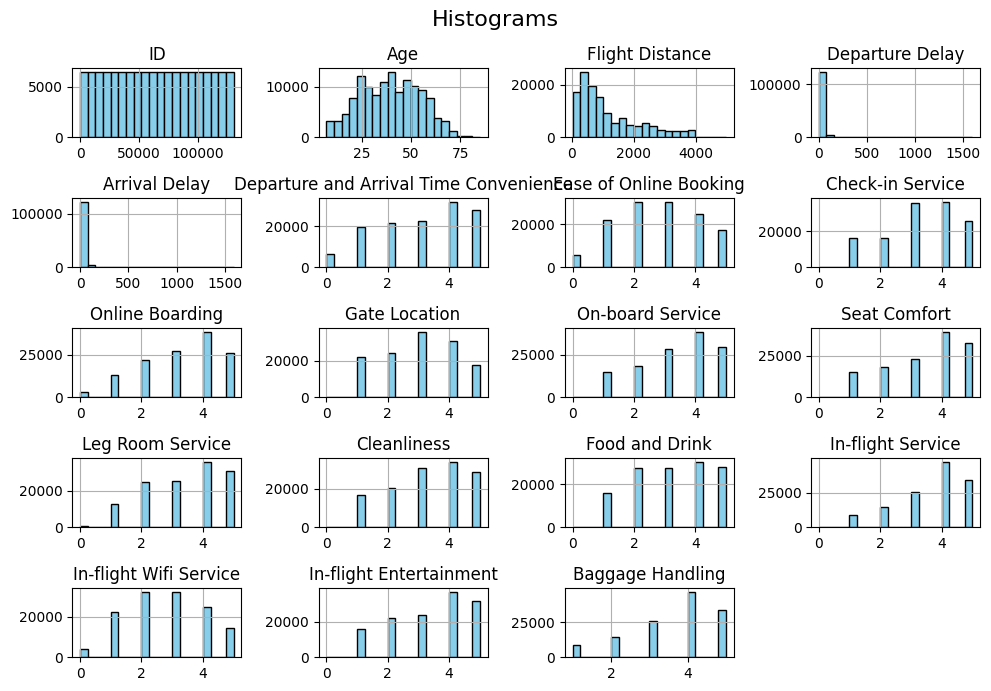

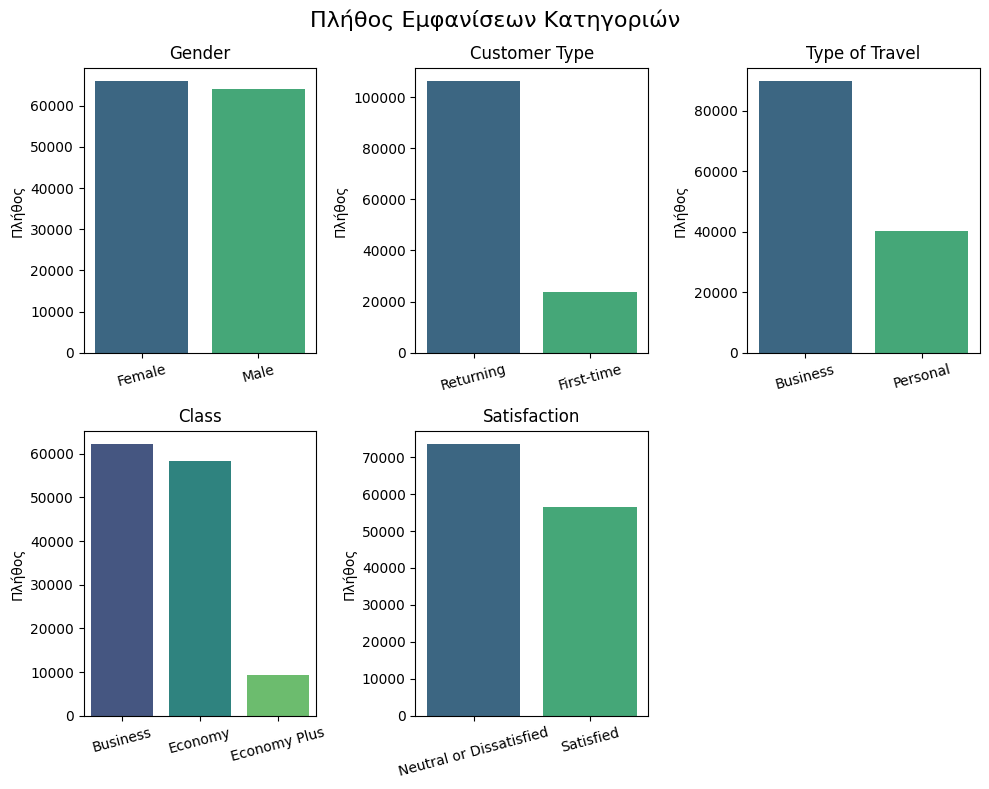

--- Κατανομή Κλάσεων Target ---
Satisfaction
Neutral or Dissatisfied    56.553742
Satisfied                  43.446258
Name: proportion, dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
df =pd.read_csv('airline_passenger_satisfaction.csv')

nuols =df.select_dtypes(include=['int64','float64']).columns
caols =df.select_dtypes(include=['object','category']).columns
df[nuols].hist(figsize=(10, 7), bins=20, color='skyblue', edgecolor='black')
plt.suptitle('Histograms', fontsize=16)
plt.tight_layout()
plt.show()

tom =3
rows =math.ceil(len(caols) / tom)
fig, axes =plt.subplots(rows,tom, figsize=(10,rows *4))
axes =axes.flatten()

for i, col in enumerate(caols):
    counts = df[col].value_counts()
    sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        legend=False,
        ax=axes[i],
        palette='viridis'
    )
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Πλήθος')
    axes[i].tick_params(axis='x', rotation=15)

for j in range(i +1,len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Πλήθος Εμφανίσεων Κατηγοριών', fontsize=16)
plt.tight_layout()
plt.show()
taol ='satisfaction' if 'satisfaction' in df.columns else 'Satisfaction'

print("--- Κατανομή Κλάσεων Target ---")
print(df[taol].value_counts(normalize=True)* 100)

Με βάση την παραπάνω ανάλυση της μεταβλητής Satisfaction ,το 56,55% των παρατηρήσεων είναι στην κατηγορία Neutral or Dissatisfied και το 43.45% στην κατηγορία Satisfied. Αφού οι δύο κλάσεις βρίσκονται κοντά στην ισοροππία του  50-50 , δεν παρατηρείται πρόβλημα μη ισορροπημένων κλάσεων . Οπότε, δεν απαιτείται η εφαρμογή τεχνικών δειγματοληψίας πριν την εκπαίδευση του μοντέλου.

In [ ]:
import pandas as pd
df =pd.read_csv('airline_passenger_satisfaction.csv')
df =df.drop(columns=['Unnamed: 0','id'],errors='ignore')

caols =df.select_dtypes(include=['object','category']).columns

for col in caols:
    df[col] =df[col].astype('category').cat.codes
print("Δεδομένα μετά την κωδικοποίηση:")
print(df.head())

Δεδομένα μετά την κωδικοποίηση:
   ID  Gender  Age  Customer Type  Type of Travel  Class  Flight Distance  \
0   1       1   48              0               0      0              821   
1   2       0   35              1               0      0              821   
2   3       1   41              1               0      0              853   
3   4       1   50              1               0      0             1905   
4   5       0   49              1               0      0             3470   

   Departure Delay  Arrival Delay  Departure and Arrival Time Convenience  \
0                2            5.0                                       3   
1               26           39.0                                       2   
2                0            0.0                                       4   
3                0            0.0                                       2   
4                0            1.0                                       3   

   ...  On-board Service  Seat Comfort  Le

Για την κωδικοποίηση των κατηγορικών μεταβλητών έγινε Label Encoding. Με τη μέθοδο αυτή, οι κατηγορίες κάθε μεταβλητής αντιστοιχίζονται σε διακριτούς ακεραίους αριθμούς.Αλλιώς, για ονομαστικές μεταβλητές χωρίς φυσική ιεραρχία, θα μπορούσε να γίνει  τεχνική One-Hot Encoding με αποτέλεσμα να αποφευχθεί η επιβολή κάποιας τεχνητής αριθμητικής διάταξης.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

taol= 'Satisfaction' if 'Satisfaction' in df.columns else 'satisfaction'

X =df.drop(columns=[taol])
y =df[taol]
X_np = X.to_numpy()
y_np =y.to_numpy()

X_train,X_test, y_train,y_test = train_test_split(
    X_np, y_np, test_size=0.30, random_state=0
)

print(f"Διαστάσεις X_train:{X_train.shape}")
print(f"Διαστάσεις X_test: {X_test.shape}")
print(f"Διαστάσεις y_train:{y_train.shape}")
print(f"Διαστάσεις y_test: {y_test.shape}")

Διαστάσεις X_train:(90916, 23)
Διαστάσεις X_test: (38964, 23)
Διαστάσεις y_train:(90916,)
Διαστάσεις y_test: (38964,)


In [ ]:
from sklearn.preprocessing import StandardScaler
nums =X.select_dtypes(include=['int64','float64']).columns
nums_idx =[X.columns.get_loc(col) for col in nums]

scaler = StandardScaler()
X_train_scaled =X_train.copy().astype(float)
X_test_scaled=X_test.copy().astype(float)
X_train_scaled[:, nums_idx] =scaler.fit_transform(X_train[:, nums_idx])
X_test_scaled[:,nums_idx] =scaler.transform(X_test[:, nums_idx])

Η κανονικοποίηση εφαρμόζεται αποκλειστικά στις αριθμητικές μεταβλητές επειδή ο  KNN βασίζεται στον υπολογισμό ευκλείδειων αποστάσεων. Χωρίς κανονικοποίηση, μεταβλητές με μεγάλο εύρος τιμών  θα υπερισχούσαν στον υπολογισμό της απόστασης σε αντίθεση με άλλους με μικρότερο εύρος ,αλλάζοντας τα αποτελέσματα της ταξινόμησης. Αντίθετα, οι κατηγορικές μεταβλητές παραμένουν ως έχουν, αφού έχουν ήδη κωδικοποιηθεί σε διακριτές τιμές και οποιαδήποτε αλλαγή τους θα χαλούσε τη σημασία της κατηγοριοποίησης χωρίς να προσφέρει κάποιο όφελος.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
if np.isnan(X_train_scaled).any():
    from sklearn.impute import SimpleImputer
    imputer = SimpleImputer(strategy='median')
    X_train_scaled = imputer.fit_transform(X_train_scaled)
    X_test_scaled = imputer.transform(X_test_scaled)
N = X_train_scaled.shape[0]
sqrt_N = int(np.sqrt(N))

k_values = [3, 5, 15, 51, 151, sqrt_N]
weights_options = ['uniform', 'distance']

results = []

for weights in weights_options:
    for k in k_values:

        knn = KNeighborsClassifier(n_neighbors=k, weights=weights, metric='euclidean')
        knn.fit(X_train_scaled, y_train)
        train_preds =knn.predict(X_train_scaled)
        test_preds =knn.predict(X_test_scaled)
        train_acc =accuracy_score(y_train, train_preds)
        test_acc =accuracy_score(y_test, test_preds)

        results.append({
            'k':k,
            'Weights':weights,
            'Train Accuracy':round(train_acc, 4),
            'Test Accuracy': round(test_acc, 4)
        })

results_df = pd.DataFrame(results)

print(f"Πλήθος παραδειγμάτων εκπαίδευσηςN ={N}(ρίζα N = {sqrt_N})\n")
print("=== Πίνακας Αποτελεσμάτων KNN ===")
print(results_df.to_string(index=False))
best_combination = results_df.loc[results_df['Test Accuracy'].idxmax()]
print("\n=== Καλύτερος Συνδυασμός ===")
print(f"k: {best_combination['k']}")
print(f"Weights: {best_combination['Weights']}")
print(f"Test Accuracy: {best_combination['Test Accuracy'] * 100:.2f}%")

KeyboardInterrupt: 

**ΜΕΡΟΣ 2**

In [ ]:
import yfinance as yf
import pandas as pd
import plotly.graph_objects as go

ticker= "EURUSD=X"
data =yf.Ticker(ticker)
df =data.history(period="10y")

df =df.drop(columns=['Volume','Dividends','Stock Splits'], errors='ignore')
stats= df[['Open','High','Low','Close']].agg(['mean','std']).T
stats.columns =['Μέση Τιμή','Τυπική Απόκλιση']
print(stats)

fig =go.Figure()
fig.add_trace(go.Scatter(x=df.index,y=df['High'], mode='lines',name='High'))
fig.add_trace(go.Scatter(x=df.index,y=df['Low'], mode='lines',name='Low'))
fig.add_trace(go.Scatter(x=df.index, y=df['Close'], mode='lines', name='Close'))
fig.update_layout(
    xaxis_title='Ημερομηνία',
    yaxis_title='Τιμή',
    width=1100,
    height=600,
    template='plotly_white'
)

fig.show()

       Μέση Τιμή  Τυπική Απόκλιση
Open    1.124531         0.054673
High    1.127838         0.054434
Low     1.121195         0.054871
Close   1.124550         0.054678


Με βάση το διάγραμμα η χρονοσειρά των τιμών του δολαρίου δεν είναι στάσιμη.Η τιμή δεν διακυμαίνεται γύρω από έναν σταθερό στατιστικό μέσο όρο, αλλά παρουσιάζει ανοδικές και καθοδικές τάσεις σε βάθος χρόνου.Η διακύμανση της τιμής δεν είναι σταθερή στον χρόνο, αφού υπάρχουν περίοδοι έντονης μεταβλητότητας  και περίοδοι ηρεμίας.

In [ ]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings("ignore")

adf_result =adfuller(df['Close'].dropna())
print("=== ADF Test ===")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

print("\n" + "="*30 + "\n")
kpss_result =kpss(df['Close'].dropna(),regression='c', nlags="auto")
print("=== KPSS Test ===")
print(f"KPSS Statistic:{kpss_result[0]:.4f}")
print(f"p-value: {kpss_result[1]:.4f}")
print("Critical Values:")
for key, value in kpss_result[3].items():
    print(f"   {key}: {value:.4f}")

=== ADF Test ===
ADF Statistic: -2.3529
p-value: 0.1555
Critical Values:
   1%: -3.4329
   5%: -2.8627
   10%: -2.5674


=== KPSS Test ===
KPSS Statistic: 0.9087
p-value: 0.0100
Critical Values:
   10%: 0.3470
   5%: 0.4630
   2.5%: 0.5740
   1%: 0.7390


Τα αποτελέσματα των  ADF και KPSS επιβεβαιώνουν τα συμπεράσματα καθώς το ADF test επιστρέφει > 0.05 και το KPSS test επιστρέφει < 0.05.Άρα, η χρονοσειρά της τιμής κλεισίματος του δολαρίου είναι μη στάσιμη.

In [ ]:
train_size =int(len(df) *0.70)
train =df.iloc[:train_size]
test =df.iloc[train_size:]

print(f"Συνολικό πλήθος παρατηρήσεων: {len(df)}")
print(f"Train Set:{len(train)}")
print(f"Test Set: {len(test)} ")

Συνολικό πλήθος παρατηρήσεων: 2601
Train Set:1820
Test Set: 781 


 H  Train RMSE  Test RMSE
 1    0.005117   0.004682
 5    0.005114   0.004686
15    0.005087   0.004708
30    0.005040   0.004706


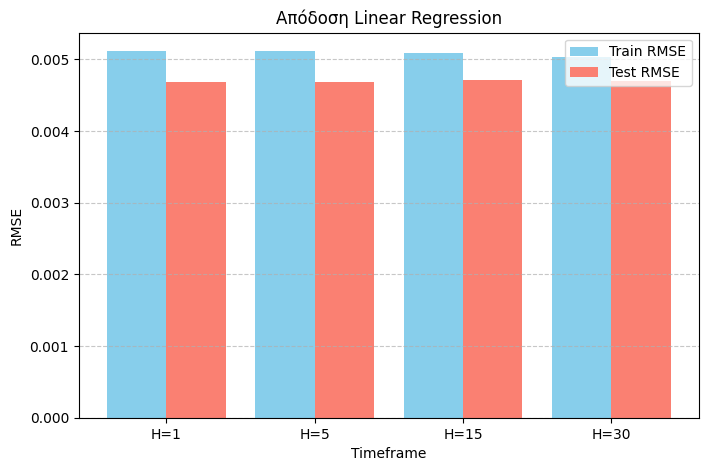

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
values =[1,5,15,30]
apt =[]

df_model =df.copy()
df_model['Target'] =df_model['Close'].shift(-1)

for H in values:
    df_temp =df_model.copy()
    for i in range(H):
        df_temp[f'Close_lag_{i}'] = df_temp['Close'].shift(i)
    df_temp =df_temp.dropna()

    feature_cols = [f'Close_lag_{i}' for i in range(H)]
    X =df_temp[feature_cols]
    y =df_temp['Target']

    train_size =int(len(df_temp) * 0.70)
    X_train,X_test = X.iloc[:train_size], X.iloc[train_size:]
    y_train,y_test = y.iloc[:train_size], y.iloc[train_size:]

    model =LinearRegression()
    model.fit(X_train, y_train)

    y_train_pred =model.predict(X_train)
    y_test_pred =model.predict(X_test)

    train_rmse =np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse =np.sqrt(mean_squared_error(y_test, y_test_pred))

    apt.append({
        'H': H,
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse
    })

apt_df =pd.DataFrame(apt)
print(apt_df.to_string(index=False))
x_labels = [f'H={h}' for h in H_values]
x_axis = np.arange(len(x_labels)
)

plt.figure(figsize=(8, 5))
plt.bar(x_axis -0.2, apt_df['Train RMSE'],0.4, label='Train RMSE',color='skyblue')
plt.bar(x_axis +0.2, apt_df['Test RMSE'], 0.4,label='Test RMSE',color='salmon')

plt.xticks(x_axis, x_labels)
plt.xlabel('Timeframe')
plt.ylabel('RMSE')
plt.title('Απόδοση Linear Regression')
plt.legend()
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.show()

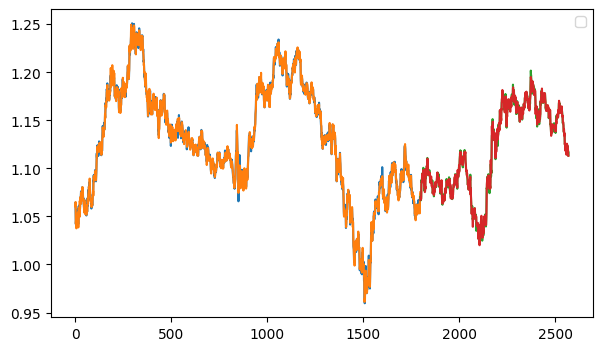

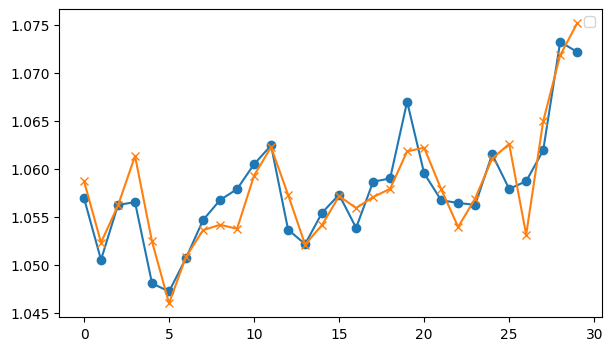

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

data = df.copy()
data['Target'] =data['Close'].shift(-1)

for i in range(1, 31):
    data[f'Lag_{i}'] =data['Close'].shift(i)
data =data.dropna()

X =data.drop(columns=['Close', 'Target'])
y =data['Target']

split =int(len(data) * 0.7)

X_train =X.iloc[:split]
X_test =X.iloc[split:]
y_train =y.iloc[:split]
y_test =y.iloc[split:]

model =LinearRegression()
model.fit(X_train,y_train)
y_pred_train =model.predict(X_train)
y_pred_test =model.predict(X_test)

plt.figure(figsize=(7, 4))
plt.plot(y_train.values)
plt.plot(y_pred_train)
plt.plot(range(len(y_train), len(y_train) + len(y_test)), y_test.values,)
plt.plot(range(len(y_train), len(y_train) + len(y_test)), y_pred_test, )
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(y_train.values[-30:], marker='o')
plt.plot(y_pred_train[-30:], marker='x')
plt.legend()
plt.show()

Παρατηρούμε ότι το μοντέλο δυσκολεύεται να προβλέψει τις απότομες αλλαγές στην τιμή. Οι προβλέψεις  προσπαθούν να ακολουθήσουν τις πραγματικές τιμές με καθυστέρηση μίας ημέρας, με  την γραμμική παλινδρόμηση ν βασίζεται στη χθεσινή τιμή για να προβλέψει τη σημερινή.

    H  Train RMSE  Test RMSE
0   1    0.005118   0.004693
1   5    0.005110   0.004692
2  15    0.005088   0.004709
3  30    0.005038   0.004723


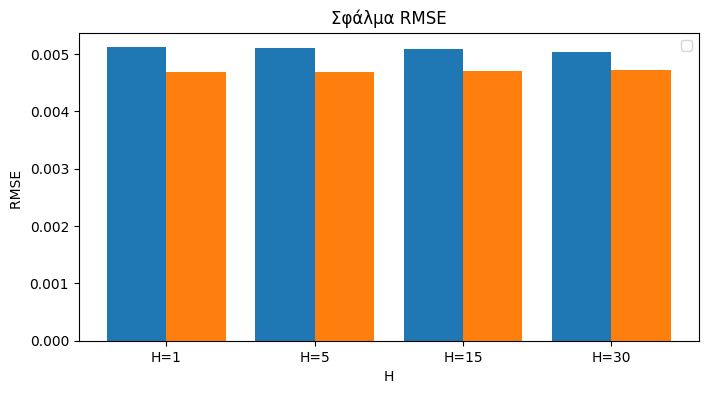

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

data =df.copy()
data['Log_Return'] = np.log(data['Close'] / data['Close'].shift(1))

data['Target_Log'] =data['Log_Return'].shift(-1)

values =[1,5,15,30]
train_errors = []
test_errors = []

for H in values:
    df_temp = data.copy()

    for i in range(1, H+ 1):
        df_temp[f'Lag_{i}'] =df_temp['Log_Return'].shift(i)

    df_temp =df_temp.dropna()

    X =df_temp[[f'Lag_{i}' for i in range(1, H + 1)]]
    y =df_temp['Target_Log']
    split =int(len(df_temp) * 0.7)

    X_train, X_test = X.iloc[:split], X.iloc[split:]
    y_train,y_test = y.iloc[:split], y.iloc[split:]

    model = LinearRegression()
    model.fit(X_train,y_train)

    pred_log_train =model.predict(X_train)
    pred_log_test = model.predict(X_test)

    close_train = df_temp['Close'].iloc[:split]
    close_test =df_temp['Close'].iloc[split:]

    pred_price_train = close_train * np.exp(pred_log_train)
    pred_price_test =close_test*np.exp(pred_log_test
                                       )

    actual_price = df_temp['Close'].shift(-1)
    actual_price_train = actual_price.iloc[:split]
    actual_price_test = actual_price.iloc[split:]
    valid_test_idx = ~actual_price_test.isna()

    train_rmse =np.sqrt(mean_squared_error(actual_price_train, pred_price_train))
    test_rmse =np.sqrt(mean_squared_error(actual_price_test[valid_test_idx], pred_price_test[valid_test_idx]))

    train_errors.append(train_rmse)
    test_errors.append(test_rmse)

results =pd.DataFrame({
    'H':values,
    'Train RMSE': train_errors,
    'Test RMSE': test_errors
})
print(results)
x = np.arange(len(values))
plt.figure(figsize=(8, 4))
plt.bar(x -0.2,train_errors, 0.4)
plt.bar(x +0.2,test_errors, 0.4)
plt.xticks(x, ['H=1', 'H=5', 'H=15', 'H=30'])
plt.xlabel('H')
plt.ylabel('RMSE ')
plt.title('Σφάλμα RMSE')
plt.legend()
plt.show()

In [ ]:
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests

data_granger = df[["Close", "Open"]].pct_change().dropna()
results =grangercausalitytests(data_granger, maxlag=4)

for lag in results:
    print(f"\n--- Lag {lag} ---")
    p_val =results[lag][0]['ssr_ftest'][1]
    f_stat =results[lag][0]['ssr_ftest'][0]
    print(f"F-statistic: {f_stat:.4f}, p-value: {p_val:.5f}")


--- Lag 1 ---
F-statistic: 0.0081, p-value: 0.92811

--- Lag 2 ---
F-statistic: 0.0089, p-value: 0.99111

--- Lag 3 ---
F-statistic: 0.1517, p-value: 0.92865

--- Lag 4 ---
F-statistic: 0.1174, p-value: 0.97637


Εφάρομσα το Granger Causality Test στις μεταβολές των μεταβλητών Close και Open για χρονικά βήματα από 1 έως 4.

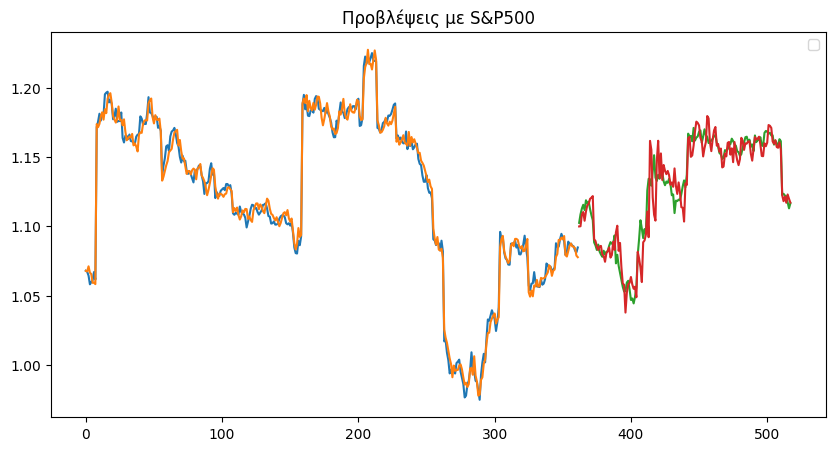

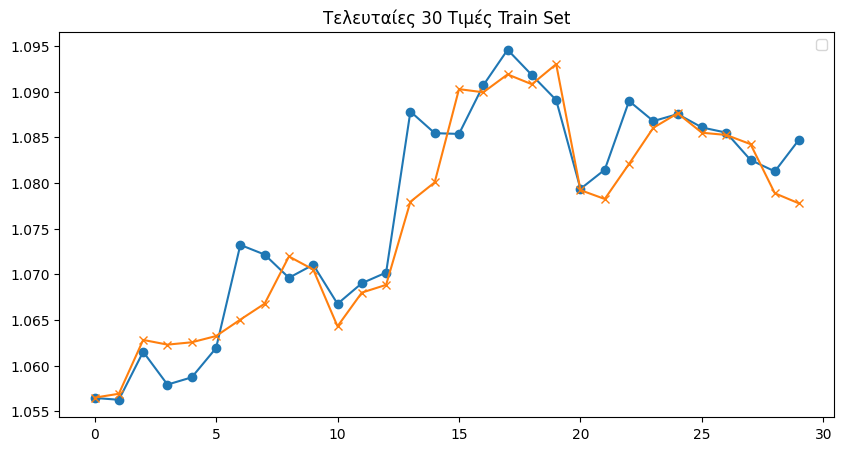

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import holidays
from sklearn.linear_model import LinearRegression
sp =yf.Ticker("^GSPC").history(period="10y")


df_clean =df.copy()
df_clean.index =df_clean.index.tz_localize(None).normalize()
sp.index = sp.index.tz_localize(None).normalize()
data9 =df_clean.copy()
data9['SP500'] = sp['Close']


data9['Day'] = data9.index.dayofweek
data9['Month'] =data9.index.month

us_holidays =holidays.US()
data9['Holiday'] =data9.index.map(lambda x: 1 if x in us_holidays else 0)
data9['Target'] =data9['Close'].shift(-1)

for i in range(1, 31):
    data9[f'Lag_{i}'] = data9['Close'].shift(i)

for i in range(1, 31):
    data9[f'SP_Lag_{i}'] =data9['SP500'].shift(i)

data9 =data9.dropna()

X =data9.drop(columns=['Open','High','Low','Close','Target'])
y =data9['Target']

split =int(len(data9) * 0.7)
X_train = X.iloc[:split]
X_test =X.iloc[split:]
y_train = y.iloc[:split]
y_test= y.iloc[split:]

model = LinearRegression()
model.fit(X_train, y_train)
pred_train =model.predict(X_train)
pred_test= model.predict(X_test)

plt.figure(figsize=(10, 5))
plt.plot(y_train.values)
plt.plot(pred_train)
plt.plot(range(len(y_train), len(y_train) +len(y_test)),y_test.values)
plt.plot(range(len(y_train), len(y_train) + len(y_test)),pred_test)
plt.title('Προβλέψεις με S&P500')
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(y_train.values[-30:], marker='o')
plt.plot(pred_train[-30:], marker='x')
plt.title('Τελευταίες 30 Τιμές Train Set')
plt.legend()
plt.show()